# 09 — Measuring the device's idle noise, and feeding it back

**Narrative points 12–13.** The regime question (notebook 08) turns on numbers no data sheet
gives: the idle dephasing rates and the round duration. This notebook shows the experiments
that measure them, the fit that turns results into a `Calibration`, and the hand-off to the
regime study — demonstrated on synthetic data with known rates, pending device access.

**Source:** `qec_timing.hardware.calibration_experiments`; programs in
`results/hardware/calibration_programs/` (`hardware.cli calib-build`).

**The experiments** (hardware_tests T2–T4 of the original repo):

| test | program | measures |
| --- | --- | --- |
| T2 readout | half the qubits in \|0⟩, half in \|1⟩, measured | p_meas0, p_meas1 |
| T3 Z-only check | targets in \|0⟩, L spectator layers, measured in Z | should not grow with L if idling is Z only |
| T4 idle law | targets in \|+⟩, L spectator layers, measured in X | γ and c per layer, from the exact emulator form |

**No delay instruction exists** (Guppy 0.21/1.x, pytket), and this toolchain cannot lower
`barrier` to QIR. Idle time is therefore spectator layers of mid-circuit measurement, and the
targets' measurement is ordered after them by feed-forward: a Z on each target conditioned
on the spectators' parity. Z is virtual on H2 (error-free); the analysis undoes it.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
from qec_timing.hardware import Calibration
from qec_timing.hardware.calibration_experiments import Rate, fit_idle, idle_pz, to_calibration_fields

truth = Calibration.load(Path("..") / "config" / "h2_1e_emulator.json")
tau = 0.01                                          # assumed: 10 ms per spectator layer
n = 8 * 4000                                        # 8 targets x 4000 shots per program
designs = {"0-64 layers": [0, 2, 4, 8, 16, 32, 64],
           "0-400 layers": [0, 25, 50, 100, 200, 300, 400]}   # omega * 400 * tau = 2.2 < pi
fits = {}
for name, layers in designs.items():
    rng = np.random.default_rng(11)
    rates = []
    for L in layers:
        pz = truth.idle_pz(L * tau)
        rates.append(Rate(int(rng.binomial(n, 0.5 * (1 - (1 - 2 * 0.003) * (1 - 2 * pz)))), n))
    fit = fit_idle(layers, rates)
    fits[name] = (layers, rates, fit)
    g, gs = fit["gamma_per_layer"] / tau, fit["gamma_per_layer_se"] / tau
    f = to_calibration_fields(fit, tau)
    print(f"{name:<13} gamma {g:.4f} +/- {gs:.4f} /s (true {truth.gamma})   "
          f"quad rate {f['quad_rate']:.4f} (true {truth.quad_rate})   chi2/dof {fit['chi2_per_dof']:.2f}")

0-64 layers   gamma 0.0052 +/- 0.0023 /s (true 0.0028)   quad rate 0.0414 (true 0.043)   chi2/dof 1.05
0-400 layers  gamma 0.0022 +/- 0.0010 /s (true 0.0028)   quad rate 0.0430 (true 0.043)   chi2/dof 1.94


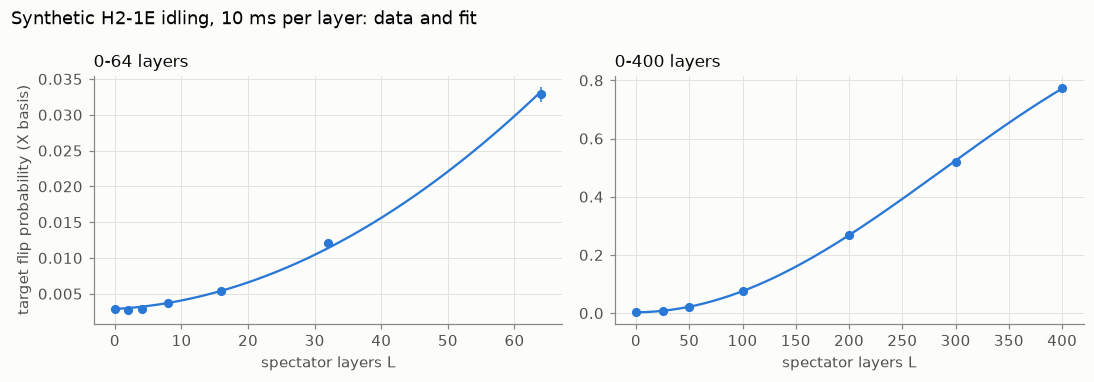

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
for ax, (name, (layers, rates, fit)) in zip(axes, fits.items()):
    L = np.array(layers); P_obs = np.array([r.p for r in rates]); se = np.array([r.se for r in rates])
    ax.errorbar(L, P_obs, yerr=se, fmt="o", color=P.SERIES[0], ms=5, lw=1)
    Lf = np.linspace(0, L[-1], 200)
    ax.plot(Lf, 0.5 * (1 - (1 - 2 * fit["spam_floor"]) * (1 - 2 * idle_pz(Lf, fit["gamma_per_layer"], fit["c_per_layer"]))),
            "-", color=P.SERIES[0], lw=1.5)
    ax.set_xlabel("spectator layers L"); ax.set_title(name, loc="left")
axes[0].set_ylabel("target flip probability (X basis)")
fig.suptitle("Synthetic H2-1E idling, 10 ms per layer: data and fit", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "09_hardware_calibration_1")

**Reading.**
- *Measured (synthetic), a design finding:* the quadratic rate is recovered well (within 1%
  at 0–400 layers). The linear rate is weakly constrained: its contribution is ~0.2% flip
  probability over 0.64 s, under the quadratic term. With 0–64 layers it comes out
  0.0052 ± 0.0023 /s (true 0.0028: consistent, but ±45%); extending to 0–400 layers, still
  inside the model's validity (ω·t < π), halves the uncertainty. Pinning γ to ~10% needs
  roughly 20× the shots at the long-L end. On H2 the quadratic term dominates at the
  timescales that matter (notebook 08), so this is the less important parameter, but the
  grid should still reach seconds of idling (`hardware.cli calib-build --layers ...`).
- `tests/test_hardware.py` pins the fit's recovery and an end-to-end `calib-fit` that writes a
  `Calibration` file from job directories.
- *The hand-off (point 13):* `hardware.cli calib-fit --readout <job> --idle <jobs> --layer-seconds τ`
  writes `config/h2_measured.json`; then
  `python -m qec_timing.studies.regime --calibration config/h2_measured.json --t-round <t_R>`
  reruns notebook 08 at the device's own numbers. Nothing else changes.
- *Open on a device:* the duration of one spectator layer and of one round (from the job's
  duration report or Quantinuum), whether the compiler keeps the programs as written
  (check on the emulator first), and gate errors (taken from the base calibration).